# Corn earworm sightings across the 2025 growing season

I picked corn earworm because corn is important to the US economy and food
supply. It's used for livestock feed, food ingredients, and ethanol
([USDA ERS](https://www.ers.usda.gov/topics/crops/corn-and-other-feed-grains/feed-grains-sector-at-a-glance)).

**Question:** Do corn earworm observations occur farther north as the growing season progresses?

Adult corn earworm moths (*Helicoverpa zea*) disperse from southern areas into
the northern US and Canada. Winter survival depends on climate, and activity
becomes more seasonal farther north ([UF/IFAS](https://ask.ifas.ufl.edu/publication/IN302)).
Here I compare monthly records from the US, Canada, and Mexico in 2025.

Run this notebook from the portfolio repository with the Earth Analytics kernel.
It reads a fixed [GBIF download](https://doi.org/10.15468/dl.7cptc8), rather than
submitting a new request. The first run downloads missing source files; later
runs use the local cache. No GBIF login or stored notebook variables are needed.
Allow 500 MB of disk space for the source files. To recreate the environment,
use `conda env create -f notebooks/corn-earworm-environment.yml` and select that
Python environment in VS Code.

In [1]:
import calendar
import json
from pathlib import Path
import shutil
import zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import pandas as pd
import requests
from bokeh.embed import file_html
from bokeh.layouts import column
from bokeh.models import (
    BooleanFilter, CDSView, ColorBar, ColumnDataSource, CustomJS, Div,
    FixedTicker, HoverTool, Label, LogColorMapper, PrintfTickFormatter, Slider,
)
from bokeh.palettes import Viridis256
from bokeh.plotting import figure
from bokeh.resources import INLINE
from IPython.display import IFrame, display
from pyproj import Transformer
from shapely.geometry import box

## Read the source data

The snapshot contains presence observations with coordinates and no GBIF
geospatial flags. All 2,207 records came from
[iNaturalist](https://www.gbif.org/dataset/50c9509d-22c7-4a22-a47d-8c48425ef4a7)
through GBIF. The US, Canada, and Mexico give us a region for comparison with
the northern migration literature; 2025 is a complete calendar year.

[RESOLVE Ecoregions 2017](https://developers.google.com/earth-engine/datasets/catalog/RESOLVE_ECOREGIONS_2017)
groups land into ecological regions with distinct species communities. These
are useful geographic summaries, although a region isn't uniform habitat.

In [2]:
# find the repository from its root or notebooks folder
project_dir = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'notebooks/corn-earworm-migration.ipynb').exists()),
    None,
)
if project_dir is None:
    raise FileNotFoundError('Run this notebook inside the portfolio repository.')
data_dir = project_dir / 'data/corn-earworm'
raw_dir = data_dir / 'raw'
asset_dir = project_dir / 'img/corn-earworm'
for folder in (raw_dir, asset_dir):
    folder.mkdir(parents=True, exist_ok=True)


def download_file(url, path):
    '''Cache a complete public download.'''
    if not path.exists():
        temporary = path.with_suffix(path.suffix + '.part')
        with requests.get(url, stream=True, timeout=(30, 120)) as response:
            response.raise_for_status()
            with temporary.open('wb') as destination:
                for chunk in response.iter_content(1024 * 1024):
                    destination.write(chunk)
        temporary.replace(path)
    return path


# reuse the exact snapshot cited in the post
gbif_path = raw_dir / 'corn-earworm-2025.tsv'
if not gbif_path.exists():
    archive_path = download_file(
        'https://api.gbif.org/v1/occurrence/download/request/0037807-260928105237408.zip',
        raw_dir / 'gbif.zip',
    )
    with zipfile.ZipFile(archive_path) as archive:
        members = [name for name in archive.namelist() if name.endswith('.csv')]
        if len(members) != 1:
            raise ValueError('Expected one GBIF occurrence table.')
        temporary = gbif_path.with_suffix('.part')
        with archive.open(members[0]) as source, temporary.open('wb') as target:
            shutil.copyfileobj(source, target)
        temporary.replace(gbif_path)

shape_path = raw_dir / 'Ecoregions2017/Ecoregions2017.shp'
shape_files = {f'Ecoregions2017{suffix}' for suffix in ['.shp', '.shx', '.dbf', '.prj']}
if not all((shape_path.parent / name).exists() for name in shape_files):
    archive_path = download_file(
        'https://storage.googleapis.com/teow2016/Ecoregions2017.zip',
        raw_dir / 'ecoregions.zip',
    )
    shape_path.parent.mkdir(exist_ok=True)
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.namelist():
            name = Path(member).name
            if name in shape_files:
                target_path = shape_path.parent / name
                temporary = target_path.with_suffix(target_path.suffix + '.part')
                with archive.open(member) as source, temporary.open('wb') as target:
                    shutil.copyfileobj(source, target)
                temporary.replace(target_path)
    if not all((shape_path.parent / name).exists() for name in shape_files):
        raise ValueError('The ecoregion archive is missing required files.')

records = pd.read_csv(gbif_path, sep='\t', low_memory=False)
regions = gpd.read_file(shape_path).to_crs(4326)
print(f'Loaded {len(records):,} records and {len(regions):,} boundary features.')

Loaded 2,207 records and 847 boundary features.


In [3]:
# keep the country scope and check fields used in the plots
selected = records.loc[records.countryCode.isin(['US', 'CA', 'MX'])].copy()
if selected.gbifID.isna().any() or selected.gbifID.duplicated().any():
    raise ValueError('GBIF identifiers must be present and unique.')
valid = (
    selected.decimalLongitude.between(-180, 180)
    & selected.decimalLatitude.between(-90, 90)
    & selected.month.isin(range(1, 13))
    & selected.year.eq(2025)
    & selected.species.eq('Helicoverpa zea')
)
observations = selected.loc[valid].copy()
observations['month'] = observations.month.astype(int)
points = gpd.GeoDataFrame(
    observations,
    geometry=gpd.points_from_xy(observations.decimalLongitude, observations.decimalLatitude),
    crs=4326,
)
monthly = observations.groupby('month').agg(
    records=('gbifID', 'size'),
    median_latitude=('decimalLatitude', 'median'),
    latitude_q25=('decimalLatitude', lambda values: values.quantile(.25)),
    latitude_q75=('decimalLatitude', lambda values: values.quantile(.75)),
).reindex(range(1, 13))
monthly['records'] = monthly.records.fillna(0).astype(int)
audit = {
    'download_doi': '10.15468/dl.7cptc8', 'worldwide_records': len(records),
    'country_scope_records': len(selected), 'invalid_records': int((~valid).sum()),
    'country_counts': observations.countryCode.value_counts().to_dict(),
    'coordinate_uncertainty_missing': int(observations.coordinateUncertaintyInMeters.isna().sum()),
    'coordinate_uncertainty_over_10km': int(observations.coordinateUncertaintyInMeters.gt(10000).sum()),
    'dataset_counts': observations.datasetKey.value_counts().to_dict(),
    'basis_of_record_counts': observations.basisOfRecord.value_counts().to_dict(),
}
print(audit)

{'download_doi': '10.15468/dl.7cptc8', 'worldwide_records': 2207, 'country_scope_records': 2198, 'invalid_records': 0, 'country_counts': {'US': 2135, 'CA': 51, 'MX': 12}, 'coordinate_uncertainty_missing': 416, 'coordinate_uncertainty_over_10km': 203, 'dataset_counts': {'50c9509d-22c7-4a22-a47d-8c48425ef4a7': 2198}, 'basis_of_record_counts': {'HUMAN_OBSERVATION': 2198}}


## Summarize records by ecoregion

Use the full boundaries for the `contains` join. Points on boundaries or outside
the polygons won't match. Keep ecoregion–month groups with at least two records
so a region isn't colored based on a single sighting. Then divide each retained
count by its ecoregion mean and month mean. Both means use the retained raw counts; missing groups aren't
filled with zero before calculating them.

This makes the map less dominated by high-count regions and months. It doesn't
measure observer effort or turn the index into abundance. The latitude figure
uses all valid country-scope records, before the spatial join and singleton filter.

In [4]:
# join before simplifying any boundaries
joined = regions[['OBJECTID', 'ECO_NAME', 'geometry']].sjoin(
    points[['gbifID', 'month', 'geometry']], how='inner', predicate='contains',
)
if joined.gbifID.duplicated().any():
    raise ValueError('A record matched multiple polygons; inspect overlaps.')
counts = joined.groupby(['OBJECTID', 'month']).size().rename('records')
assert counts.sum() == len(joined)
retained = counts.loc[counts.gt(1)].to_frame()
assert retained.records.sum() + counts.eq(1).sum() == len(joined)
region_means = retained.records.groupby(level='OBJECTID').mean()
month_means = retained.records.groupby(level='month').mean()
retained['index'] = (
    retained.records.div(region_means, level='OBJECTID')
    .div(month_means, level='month')
)
assert np.isfinite(retained['index']).all() and retained['index'].gt(0).all()
mapped_months = retained.groupby('month').agg(
    mapped_records=('records', 'sum'), mapped_ecoregions=('records', 'size'),
).reindex(range(1, 13), fill_value=0)
monthly = monthly.join(mapped_months)
audit.update({
    'matched_records': len(joined), 'unmatched_records': len(points) - len(joined),
    'singleton_groups': int(counts.eq(1).sum()), 'retained_groups': len(retained),
    'mapped_records': int(retained.records.sum()),
    'mapped_ecoregions': retained.index.get_level_values('OBJECTID').nunique(),
})
print(audit)
display(monthly.round(2))

{'download_doi': '10.15468/dl.7cptc8', 'worldwide_records': 2207, 'country_scope_records': 2198, 'invalid_records': 0, 'country_counts': {'US': 2135, 'CA': 51, 'MX': 12}, 'coordinate_uncertainty_missing': 416, 'coordinate_uncertainty_over_10km': 203, 'dataset_counts': {'50c9509d-22c7-4a22-a47d-8c48425ef4a7': 2198}, 'basis_of_record_counts': {'HUMAN_OBSERVATION': 2198}, 'matched_records': 2181, 'unmatched_records': 17, 'singleton_groups': 58, 'retained_groups': 150, 'mapped_records': 2123, 'mapped_ecoregions': 39}


,records,median_latitude,latitude_q25,latitude_q75,mapped_records,mapped_ecoregions
month,,,,,,
1,3,27.67,24.04,27.67,2,1
2,5,30.23,30.10,40.13,0,0
3,27,29.67,27.66,30.20,24,4
4,34,31.13,29.87,32.85,32,8
5,38,30.53,29.58,33.78,30,7
6,134,32.76,30.35,33.63,125,12
7,262,33.13,32.62,35.50,253,19
8,407,38.59,35.06,41.26,396,25
9,687,38.95,35.24,41.17,678,39


## Recorded locations shift north in late summer

The chart shows record counts above and recorded latitude below. Vertical bars
span the middle half of the observations; they aren't confidence intervals.
Small winter samples need caution. Neither panel follows individual insects.

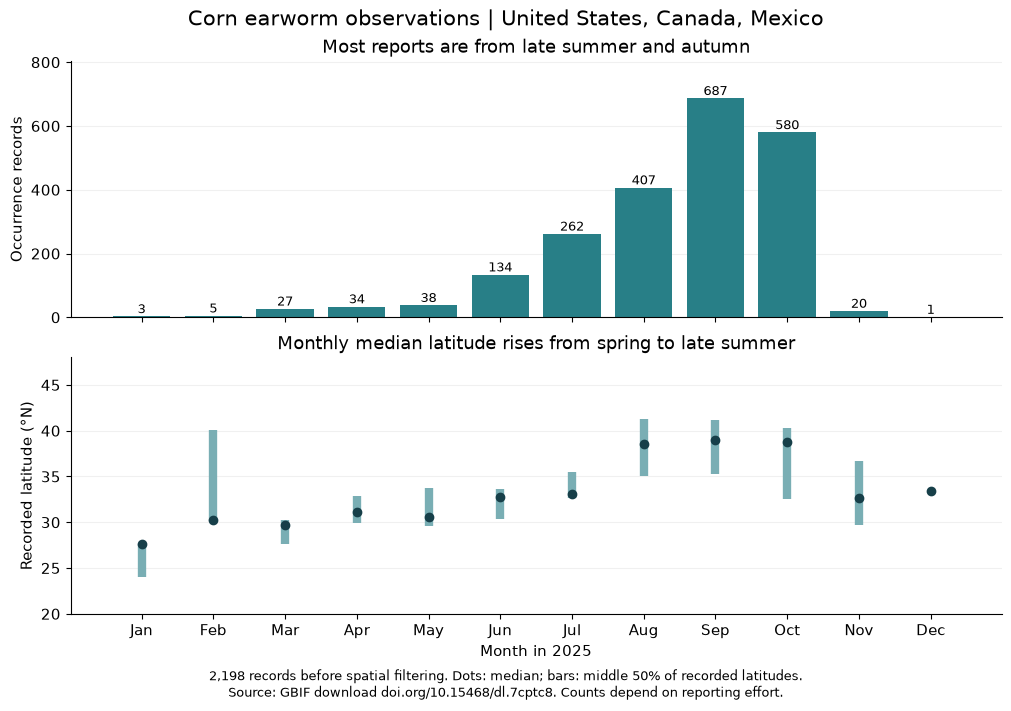

In [5]:
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
fig, (ax_count, ax_lat) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, layout='constrained')
months = monthly.index.to_numpy()
ax_count.bar(months, monthly.records, color='#287f87')
for month, count in monthly.records.items():
    ax_count.text(month, count + 10, f'{count:,}', ha='center', fontsize=9)
ax_count.set(ylabel='Occurrence records', ylim=(0, monthly.records.max() * 1.17),
             title='Most reports are from late summer and autumn')
ax_lat.vlines(months, monthly.latitude_q25, monthly.latitude_q75,
              color='#79aeb4', linewidth=6)
ax_lat.scatter(months, monthly.median_latitude, color='#173f49', zorder=3)
ax_lat.set(ylabel='Recorded latitude (°N)', xlabel='Month in 2025', ylim=(20, 48),
           title='Monthly median latitude rises from spring to late summer')
ax_lat.set_xticks(months, [calendar.month_abbr[m] for m in months])
for ax in (ax_count, ax_lat):
    ax.grid(axis='y', alpha=.18)
    ax.set_axisbelow(True)
fig.suptitle('Corn earworm observations | United States, Canada, Mexico', fontsize=15)
fig.supxlabel(
    '2,198 records before spatial filtering. Dots: median; bars: middle 50% of recorded latitudes.\n'
    'Source: GBIF download doi.org/10.15468/dl.7cptc8. Counts depend on reporting effort.', fontsize=9,
)
fig.savefig(asset_dir / 'seasonal-coverage.png', dpi=160, facecolor='white')
plt.show()
plt.close(fig)

## Map monthly ecoregion patterns

Simplify a copy by 0.05 degrees for display. Keep the same extent and logarithmic
color limits across months. Brighter regions have a higher normalized index,
not necessarily more records. Gray means no retained group that month.
The map colors whole ecoregions within the view; it doesn't show occupied area.
Web Mercator provides familiar coordinates but distorts area.

In [6]:
# simplify only the display copy
bounds = (-126, 14, -60, 55)
display_regions = regions.cx[bounds[0]:bounds[2], bounds[1]:bounds[3]][
    ['OBJECTID', 'ECO_NAME', 'geometry']
].copy()
simplified = display_regions.geometry.simplify(.05, preserve_topology=False)
collapsed = simplified.is_empty
simplified.loc[collapsed] = display_regions.loc[collapsed].geometry.simplify(
    .05, preserve_topology=True,
)
display_regions.geometry = simplified
display_regions = display_regions.clip(box(*bounds)).to_crs(3857)
mapped = display_regions.merge(retained.reset_index(), on='OBJECTID', validate='one_to_many')
assert len(mapped) == len(retained)
transformer = Transformer.from_crs(4326, 3857, always_xy=True)
xmin, ymin = transformer.transform(bounds[0], bounds[1])
xmax, ymax = transformer.transform(bounds[2], bounds[3])
limits = (float(retained['index'].min()), float(retained['index'].max()))
labels = [('CANADA', -107, 52), ('UNITED STATES', -104, 40), ('MEXICO', -104, 24)]

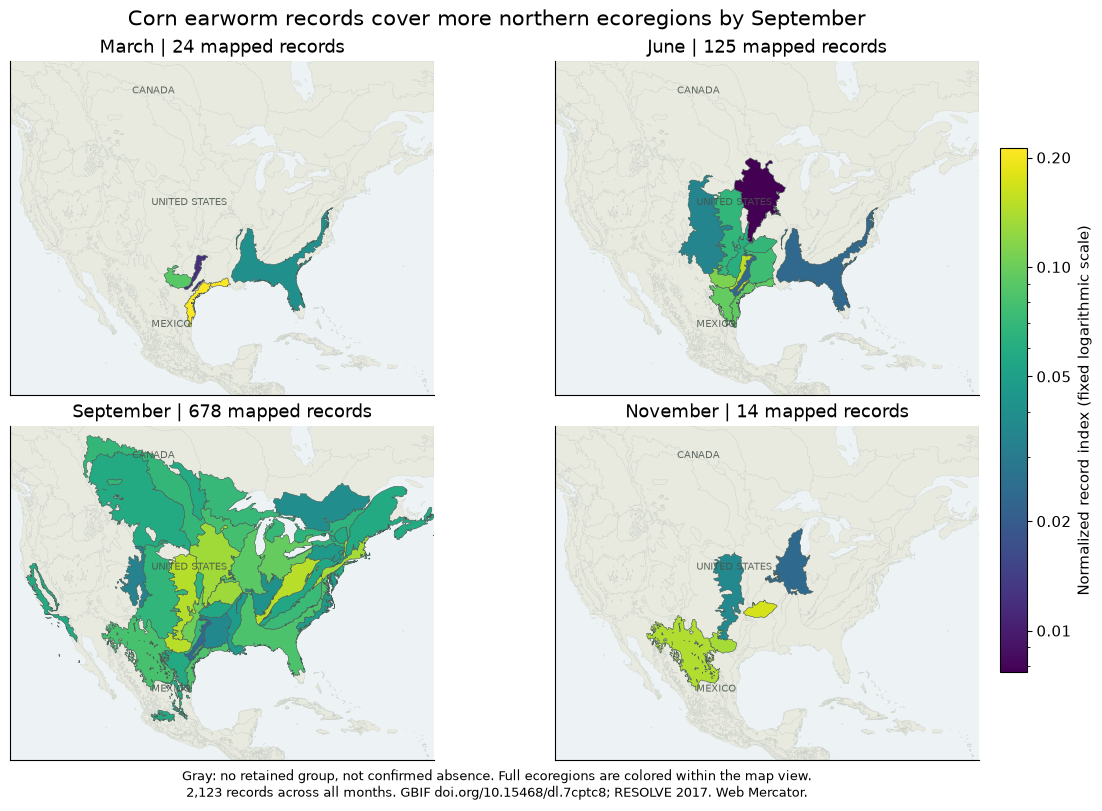

In [7]:
# use four months to show the map without a slider
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
normalizer = LogNorm(vmin=limits[0], vmax=limits[1])
for ax, month in zip(axes.flat, [3, 6, 9, 11]):
    display_regions.plot(ax=ax, color='#e8e9df', edgecolor='#c5ccc4', linewidth=.18)
    frame = mapped.loc[mapped.month.eq(month)]
    frame.plot(ax=ax, column='index', cmap='viridis', norm=normalizer,
               edgecolor='#485b55', linewidth=.4)
    for label, lon, lat in labels:
        x, y = transformer.transform(lon, lat)
        ax.text(x, y, label, fontsize=7, color='#47534c', alpha=.85)
    ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax),
           title=f'{calendar.month_name[month]} | {int(frame.records.sum()):,} mapped records')
    ax.set_facecolor('#edf3f5')
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle('Corn earworm records cover more northern ecoregions by September', fontsize=15)
bar = fig.colorbar(plt.cm.ScalarMappable(norm=normalizer, cmap='viridis'),
                   ax=axes.ravel().tolist(), shrink=.75, pad=.02,
                   ticks=[.01, .02, .05, .10, .20], format='%.2f')
bar.set_label('Normalized record index (fixed logarithmic scale)')
fig.supxlabel(
    'Gray: no retained group, not confirmed absence. Full ecoregions are colored within the map view.\n'
    '2,123 records across all months. GBIF doi.org/10.15468/dl.7cptc8; RESOLVE 2017. Web Mercator.', fontsize=9,
)
fig.savefig(asset_dir / 'seasonal-map.png', dpi=160, facecolor='white')
plt.show()
plt.close(fig)

In [8]:
def polygon_data(frame):
    '''Convert polygons and their holes for Bokeh.'''
    data = {'xs': [], 'ys': []}
    for name in ['ECO_NAME', 'month', 'records', 'index']:
        if name in frame:
            data[name] = frame[name].tolist()
    for geometry in frame.geometry:
        parts = [geometry] if geometry.geom_type == 'Polygon' else geometry.geoms
        polygons = [part for part in parts if part.geom_type == 'Polygon' and not part.is_empty]
        rings = [[part.exterior, *part.interiors] for part in polygons]
        data['xs'].append([[list(ring.xy[0]) for ring in group] for group in rings])
        data['ys'].append([[list(ring.xy[1]) for ring in group] for group in rings])
    assert all(data['xs']), 'A map group lost its geometry.'
    return data


# keep every month in the export, including months with no retained groups
plot = figure(
    title='Corn earworm observations | 2025',
    x_range=(xmin, xmax), y_range=(ymin, ymax),
    x_axis_type='mercator', y_axis_type='mercator',
    sizing_mode='scale_width', width=800, height=600, min_width=300,
    background_fill_color='#edf3f5', tools='pan,wheel_zoom,reset,save',
    active_scroll='wheel_zoom', match_aspect=True,
)
plot.multi_polygons('xs', 'ys', source=ColumnDataSource(polygon_data(display_regions)),
                     fill_color='#e8e9df', line_color='#c5ccc4', line_width=.3)
source = ColumnDataSource(polygon_data(mapped))
month_filter = BooleanFilter([month == 3 for month in source.data['month']])
mapper = LogColorMapper(palette=Viridis256, low=limits[0], high=limits[1])
colored = plot.multi_polygons(
    'xs', 'ys', source=source, view=CDSView(filter=month_filter),
    fill_color={'field': 'index', 'transform': mapper},
    line_color='#485b55', line_width=.5,
)
plot.add_tools(HoverTool(renderers=[colored], tooltips=[
    ('Ecoregion', '@ECO_NAME'), ('Records', '@records{0,0}'), ('Normalized index', '@index{0.00000}'),
]))
# use distinct decimal labels on the log scale
plot.add_layout(ColorBar(
    color_mapper=mapper, ticker=FixedTicker(ticks=[.01, .02, .05, .10, .20]),
    formatter=PrintfTickFormatter(format='%.2f'), title='Record index (log scale)',
), 'right')
plot.xaxis.axis_label, plot.yaxis.axis_label = 'Longitude', 'Latitude'
for label, lon, lat in labels:
    x, y = transformer.transform(lon, lat)
    plot.add_layout(Label(x=x, y=y, text=label, text_font_size='9px', text_color='#47534c'))
messages = []
for month, row in monthly.iterrows():
    message = (f'<b>{calendar.month_name[month]}</b>: {int(row.mapped_records):,} records mapped '
               f'in {int(row.mapped_ecoregions)} ecoregions '
               f'({int(row.records):,} records before spatial filtering).')
    if row.mapped_ecoregions == 0:
        message += ' No groups passed the filter; this does not establish absence.'
    messages.append(message)
status = Div(
    text=messages[2], sizing_mode='stretch_width', margin=(0, 18, 12, 18),
    styles={'color': '#173f49', 'font-size': '13px'},
)
# make the month control easy to find and use
slider_css = '''
:host {
    --slider-size: 12px;
    --handle-width: 32px;
    --handle-height: 32px;
}
.bk-slider-title {
    color: #173f49; font-size: 18px; font-weight: 700;
    white-space: normal; margin-bottom: 10px;
}
.noUi-target {
    background: #a8c8ca; border: 1px solid #527a80;
    border-radius: 8px; box-shadow: none;
}
.noUi-connects { border-radius: 7px; }
.noUi-handle {
    background: #f3ba47; border: 2px solid #173f49;
    border-radius: 50%; box-shadow: 0 2px 5px #173f4940;
}
.noUi-handle:focus-visible {
    outline: 3px solid #173f49; outline-offset: 4px;
}
.noUi-handle:hover, .noUi-handle.noUi-active {
    box-shadow: 0 0 0 4px #f3ba4740;
}
'''
slider = Slider(
    title='Month: March', start=1, end=12, value=3, step=1,
    show_value=False, tooltips=False, sizing_mode='stretch_width',
    bar_color='#176b73', stylesheets=[slider_css], margin=(0, 24, 10, 24),
)
slider_hint = Div(
    text=('Move the slider to compare months. '
          'Hover over colored regions for record counts.'),
    sizing_mode='stretch_width',
    margin=(12, 18, 0, 18),
    styles={'color': '#173f49', 'font-size': '14px', 'font-weight': '600'},
)
month_controls = column(
    slider_hint, slider, status, sizing_mode='stretch_width', spacing=6,
    styles={'background-color': '#e7f3f2', 'border': '2px solid #527a80',
            'border-radius': '12px'},
)
slider.js_on_change('value', CustomJS(
    args=dict(source=source, month_filter=month_filter, status=status,
              messages=messages, month_names=list(calendar.month_name)),
    code='''
        const month = cb_obj.value;
        month_filter.booleans = source.data.month.map(value => value === month);
        cb_obj.title = 'Month: ' + month_names[month];
        status.text = messages[month - 1];
    ''',
))
caption = Div(text=(
    '<p>Colors use the same logarithmic scale '
    'in every month. Gray means no retained group, not confirmed absence. The index rescales '
    'record counts; it is not animal abundance. Whole ecoregions are colored within the view.</p>'
    '<p>Sources: <a href="https://doi.org/10.15468/dl.7cptc8">GBIF download</a> and '
    '<a href="https://developers.google.com/earth-engine/datasets/catalog/RESOLVE_ECOREGIONS_2017">'
    'RESOLVE Ecoregions 2017</a>. US, Canada, Mexico; 2025. Web Mercator distorts area.</p>'
), sizing_mode='stretch_width')
# put the control before the map
layout = column(month_controls, plot, caption, sizing_mode='stretch_width',
                max_width=800, spacing=12)
map_path = asset_dir / 'migration-map.html'
html = file_html(layout, INLINE, 'Corn earworm observations by month')
map_path.write_text('\n'.join(line.rstrip() for line in html.splitlines()) + '\n',
                    encoding='utf-8')
display(IFrame(src='../img/corn-earworm/migration-map.html', width='100%', height=950))
print('Saved offline interactive map:', map_path.relative_to(project_dir))

Saved offline interactive map: img\corn-earworm\migration-map.html


## What the results support

The median recorded latitude increases from 29.7°N in March to 38.9°N in
September. That fits the species' known seasonal dispersal, but it also reflects
where people report observations. Of the 2,198 country-scope records, 2,135 are
from the US. The download has no life-stage column, so we can't isolate adults.

The map retains 2,123 records across 39 ecoregions. February and December have
no retained groups after filtering, so this isn't a complete picture of the
annual migration cycle. The lower November median comes from just 20 records.
Some locations are imprecise: 416 records lack uncertainty estimates and 203
report uncertainty above 10 km. That can affect ecoregion assignments.

A [2026 isotope study](https://doi.org/10.3389/finsc.2026.1726127) found evidence
that some late-season moths collected in Florida came from farther north. Our
occurrence records can't establish those journeys. They show a seasonal change
in reported locations that we can compare with that research.

In [9]:
# check whether coarse locations drive the latitude pattern
precise = observations.loc[observations.coordinateUncertaintyInMeters.between(0, 10000)]
sensitivity = pd.DataFrame({
    'all_records': monthly.median_latitude,
    'known_uncertainty_at_most_10km': precise.groupby('month').decimalLatitude.median(),
})
display(sensitivity.loc[[3, 6, 9, 11]].round(2))
monthly.to_csv(data_dir / 'monthly-summary.csv', index_label='month')
sensitivity.to_csv(data_dir / 'latitude-sensitivity.csv', index_label='month')
(data_dir / 'audit.json').write_text(json.dumps(audit, indent=2), encoding='utf-8')
print('Saved monthly summaries and data checks.')

Saved monthly summaries and data checks.


,all_records,known_uncertainty_at_most_10km
month,,
3,29.67,29.67
6,32.76,32.62
9,38.95,39.08
11,32.61,32.32


Keeping only records with known coordinate uncertainty of at most 10 km gives
similar medians for March, June, September, and November. The broad latitude
pattern remains, though this check doesn't validate individual ecoregion matches.